# BRFSS 2015 — Least Squares et Ridge Regression

Nous comparons Least Squares et Ridge avec le **F1-score de la classe +1**. Nous explorons plusieurs valeurs de λ et visualisons leurs effets.

**Protocole sans fuite de données :** `prepare_data()` produit un entraînement (80 %) et une validation (20 %) avec preprocessing ajusté uniquement sur l’entraînement. Nous subdivisons la validation en **calibration** (choix de λ et du seuil) et **évaluation finale** (jamais utilisée pour choisir les paramètres). Le test de compétition n’est pas utilisé ici.

## 1. Imports et configuration

Place ce notebook à la racine de `project_1_ML`, avec `preprocessing.py` et le dossier `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from preprocessing import load_feature_names
from implementations import (
    least_squares,
    ridge_regression
)
from helpers import load_csv_data
from preprocessing import load_feature_names, clean_and_standardize

SEED = 42

## 2. Préparation et vérification des classes

Le preprocessing gère l’imputation, l’encodage et la standardisation. Aucune observation n’est supprimée.

In [2]:
# Load data
data_path = "data"
x, x_test, y, _, test_ids = load_csv_data(data_path)

# Load feature names
names = load_feature_names(data_path)

# Split train / validation (80% / 20%)
np.random.seed(42)
indices = np.random.permutation(len(y))

split = int(0.8 * len(y))

train_idx = indices[:split]
val_idx = indices[split:]

X_train_raw = x[train_idx]
X_val_raw = x[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

X_train, X_val = clean_and_standardize(
    X_train_raw,
    X_val_raw,
    names
)

## 3. Diviser la validation en calibration et évaluation
Comme expliquer précédemment `X_cal` et `Y_cal`serveront de data pour calibrer et chercher le `lambda`et le `threshold`le plus optimal. Ensuite `X_eval` et `Y_eval`serveront quant à eux d'évaluation final (F1,Recall,Precision) 

In [144]:
def stratified_indices(y, fraction=0.5, seed=123):
    rng = np.random.default_rng(seed)
    left, right = [], []
    for label in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == label))
        n_left = int(round(len(idx) * fraction))
        left.extend(idx[:n_left]); right.extend(idx[n_left:])
    return rng.permutation(left), rng.permutation(right)

cal_idx, eval_idx = stratified_indices(y_val, fraction=0.5, seed=SEED + 1)
X_cal, y_cal = X_val[cal_idx], y_val[cal_idx]
X_eval, y_eval = X_val[eval_idx], y_val[eval_idx]
print("Calibration :", X_cal.shape, "positifs :", np.mean(y_cal == 1))
print("Évaluation :", X_eval.shape, "positifs :", np.mean(y_eval == 1))

Calibration : (32814, 154) positifs : 0.08990065216066313
Évaluation : (32813, 154) positifs : 0.08990339194831316


## 4. Métriques adaptées au déséquilibre

**Important :** les modèles LS/Ridge prédisent un **score continu**, pas directement −1/+1. Nous classons `+1` si `score >= seuil`, sinon `−1`. Le seuil 0 est naturel pour des cibles −1/+1, mais **pas nécessairement optimal pour le F1**.

In [145]:
def predict_labels(scores, threshold=0.0):
    return np.where(np.asarray(scores) >= threshold, 1, -1)


def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == -1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == -1)))
    tn = int(np.sum((y_true == -1) & (y_pred == -1)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    accuracy = (tp + tn) / len(y_true)
    return dict(F1=f1, Precision=precision, Recall=recall,
                Accuracy=accuracy, TP=tp, FP=fp, FN=fn, TN=tn)


def best_f1_threshold(y_true, scores):
    """Recherche exacte du meilleur seuil F1 sur calibration"""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="stable")
    s = scores[order]
    positive = (y_true[order] == 1).astype(int)
    tp = np.cumsum(positive)
    fp = np.arange(1, len(s) + 1) - tp
    total_pos = positive.sum()
    f1 = 2 * tp / np.maximum(2 * tp + fp + total_pos - tp, 1)
    valid_end = np.r_[s[:-1] > s[1:], True]
    eligible = np.flatnonzero(valid_end)
    best = eligible[np.argmax(f1[eligible])]
    return float(s[best]), float(f1[best])

baseline = classification_metrics(y_eval, np.full(len(y_eval), -1))
print("Baseline toujours -1 :", baseline)

Baseline toujours -1 : {'F1': 0.0, 'Precision': 0.0, 'Recall': 0.0, 'Accuracy': 0.9100966080516868, 'TP': 0, 'FP': 0, 'FN': 2950, 'TN': 29863}


## 5. Least Squares

In [165]:
from scipy.linalg import qr
import numpy as np

# Identifier les colonnes linéairement indépendantes
Q, R, piv = qr(X_train, pivoting=True, mode="economic")

rank = np.linalg.matrix_rank(X_train)

independent_cols = piv[:rank]
dependent_cols = piv[rank:]

#print("Independent columns:", independent_cols)
#print("Dependent columns:", dependent_cols)

# Supprimer les colonnes dépendantes
X_train_fixed = X_train[:, independent_cols]
X_cal_fixed = X_cal[:, independent_cols]
X_eval_fixed = X_eval[:, independent_cols]

# Least Squares
w_ls, ls_train_loss = least_squares(
    y_train.astype(float),
    X_train_fixed
)

# Calcul des scores
ls_cal_scores = X_cal_fixed @ w_ls
ls_eval_scores = X_eval_fixed @ w_ls

# Recherche du meilleur seuil sur calibration
ls_threshold, ls_cal_f1 = best_f1_threshold(
    y_cal,
    ls_cal_scores
)

# Évaluation avec seuil par défaut
ls_eval_default = classification_metrics(
    y_eval,
    predict_labels(ls_eval_scores, 0.0)
)

# Évaluation avec seuil optimisé
ls_eval_tuned = classification_metrics(
    y_eval,
    predict_labels(ls_eval_scores, ls_threshold)
)

# Affichage des résultats
print(
    f"Least Squares : demi-MSE train = {ls_train_loss:.5f} ; "
    f"seuil calibré = {ls_threshold:.5f}"
)

print(
    pd.DataFrame([
        {"Modèle": "LS, seuil 0", **ls_eval_default},
        {"Modèle": "LS, seuil calibré", **ls_eval_tuned}
    ]).set_index("Modèle").round(4)
)
df_ls = pd.DataFrame([
        {"Modèle": "LS, seuil 0", **ls_eval_default},
        {"Modèle": "LS, seuil calibré", **ls_eval_tuned}
    ]).set_index("Modèle").round(4)

df_ls.to_csv("plot/df_ls.csv")

Independent columns: [118   0  69  99  64  17  48 130  23  72  29  18 123  16  65   3  13  10
  56 125 153   2  55  19  22  14 104  20  40   8  34  77 132   5  15 131
  31  47  66  90  60 105 149  36  28  24   9  21  62  67  35  53   6 107
  71  78  45  30  41  88 117  11  94  82 106  26  38 129  46  37 138  44
  32  57  93 126  50  61  42   7  52 108  49 103  39  12  54 112  43  51
 137  68  58  59  73  25   4 144  97  33 122  91 111  75 148  96  86 128
  80  92 145  95 150  70 102  74 100 127  79 146 152 121 110 114  83 147
 113  89  27 142 109 115  63 116  98  87 140 151  85 101  81 136  84 133
 135  76 143 134   1 124]
Dependent columns: [120 141 139 119]
Least Squares : demi-MSE train = 0.13669 ; seuil calibré = -0.57654
                       F1  Precision  Recall  Accuracy    TP    FP    FN  \
Modèle                                                                     
LS, seuil 0        0.0054     0.7273  0.0027    0.9102     8     3  2942   
LS, seuil calibré  0.4089     0.3280

## 6. Ridge Regression


In [166]:
n_train, n_features = X_train.shape
ridge_gram = X_train.T.dot(X_train)
ridge_rhs = X_train.T.dot(y_train.astype(float))
lambdas = np.logspace(-6, 2, 30)
results = []
ridge_weights = {}
ridge_thresholds = {}

for lam in lambdas:
    # Équivalent exact de ridge_regression(y_train, X_train, lam).
    w = np.linalg.solve(ridge_gram + 2 * n_train * lam * np.identity(n_features), ridge_rhs)
    ridge_weights[float(lam)] = w
    cal_scores = X_cal @ w
    threshold, cal_f1 = best_f1_threshold(y_cal, cal_scores)
    ridge_thresholds[float(lam)] = threshold
    at_zero = classification_metrics(y_cal, predict_labels(cal_scores, 0.0))
    tuned = classification_metrics(y_cal, predict_labels(cal_scores, threshold))
    results.append({
        "lambda": float(lam),
        "F1_cal_seuil_0": at_zero["F1"],
        "F1_cal_optimise": cal_f1,
        "precision_cal": tuned["Precision"],
        "recall_cal": tuned["Recall"],
        "seuil": threshold,
        "norme_poids": np.linalg.norm(w),
        "MSE_cal": 2 * compute_loss(y_cal, X_cal, w),
    })

ridge_df = pd.DataFrame(results)
best_row = ridge_df.loc[ridge_df["F1_cal_optimise"].idxmax()]
best_lambda = float(best_row["lambda"])
best_ridge_threshold = ridge_thresholds[best_lambda]
print(f"Meilleur λ (calibration) = {best_lambda:.6g}")
print(f"Seuil optimal (calibration) = {best_ridge_threshold:.6f}")
print(f"F1 calibration = {best_row['F1_cal_optimise']:.4f}")
display(ridge_df.round(4))
ridge_df.to_csv('plot/ridge_df.csv')

Meilleur λ (calibration) = 1.26896e-05
Seuil optimal (calibration) = -0.582888
F1 calibration = 0.4180


,lambda,F1_cal_seuil_0,F1_cal_optimise,precision_cal,recall_cal,seuil,norme_poids,MSE_cal
0,0.0000,0.0061,0.4175,0.3342,0.5559,-0.5765,4.0418,0.2769
1,0.0000,0.0061,0.4177,0.3337,0.5583,-0.5776,3.9564,0.2769
2,0.0000,0.0061,0.4176,0.3327,0.5607,-0.5791,3.8055,0.2769
3,0.0000,0.0061,0.4177,0.3323,0.5620,-0.5805,3.5521,0.2769
4,0.0000,0.0054,0.4180,0.3314,0.5658,-0.5829,3.1621,0.2770
5,0.0000,0.0054,0.4179,0.3305,0.5681,-0.5852,2.6370,0.2771
6,0.0000,0.0054,0.4179,0.3341,0.5576,-0.5804,2.0490,0.2773
7,0.0001,0.0034,0.4161,0.3373,0.5427,-0.5743,1.5245,0.2776
8,0.0002,0.0034,0.4161,0.3397,0.5369,-0.5714,1.1627,0.2778
9,0.0003,0.0027,0.4157,0.3356,0.5461,-0.5769,0.9717,0.2780


## 7. Figures


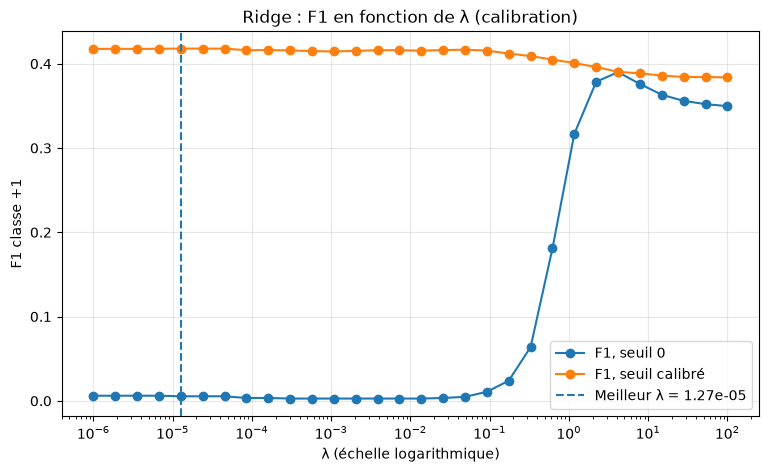

In [178]:
plt.figure(figsize=(9, 5))
plt.semilogx(ridge_df["lambda"], ridge_df["F1_cal_seuil_0"], "o-", label="F1, seuil 0")
plt.semilogx(ridge_df["lambda"], ridge_df["F1_cal_optimise"], "o-", label="F1, seuil calibré")
plt.axvline(best_lambda, linestyle="--", label=f"Meilleur λ = {best_lambda:.3g}")
plt.xlabel("λ (échelle logarithmique)"); plt.ylabel("F1 classe +1")
plt.title("Ridge : F1 en fonction de λ (calibration)")
plt.legend(); plt.grid(alpha=0.3) 
plt.savefig('plot/Ridge : F1 en fonction de λ (calibration).png', bbox_inches='tight')
plt.show()

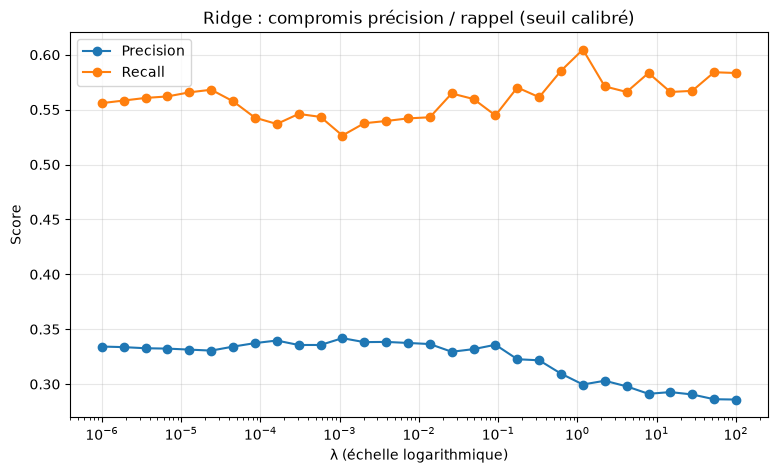

In [179]:
plt.figure(figsize=(9, 5))
plt.semilogx(ridge_df["lambda"], ridge_df["precision_cal"], "o-", label="Precision")
plt.semilogx(ridge_df["lambda"], ridge_df["recall_cal"], "o-", label="Recall")
plt.xlabel("λ (échelle logarithmique)"); plt.ylabel("Score")
plt.title("Ridge : compromis précision / rappel (seuil calibré)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('plot/Ridge : compromis précision_rappel (seuil calibré).png', bbox_inches='tight')

plt.show()

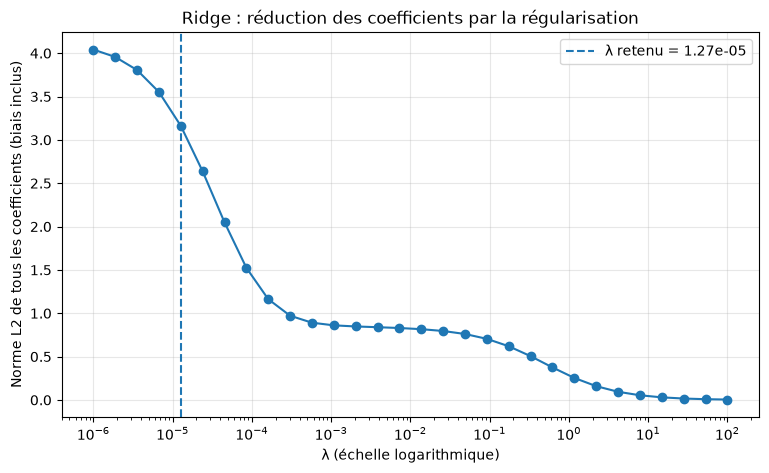

In [180]:
plt.figure(figsize=(9, 5))
plt.semilogx(ridge_df["lambda"], ridge_df["norme_poids"], "o-")
plt.axvline(best_lambda, linestyle="--", label=f"λ retenu = {best_lambda:.3g}")
plt.xlabel("λ (échelle logarithmique)")
plt.ylabel("Norme L2 de tous les coefficients (biais inclus)")
plt.title("Ridge : réduction des coefficients par la régularisation")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('plot/Ridge : réduction des coefficients par la régularisation.png', bbox_inches='tight')
plt.show()

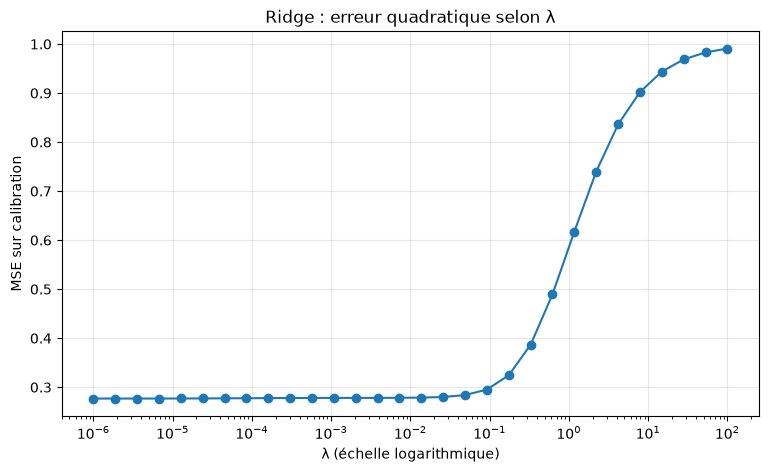

In [181]:
plt.figure(figsize=(9, 5))
plt.semilogx(ridge_df["lambda"], ridge_df["MSE_cal"], "o-")
plt.xlabel("λ (échelle logarithmique)"); plt.ylabel("MSE sur calibration")
plt.title("Ridge : erreur quadratique selon λ")
plt.grid(alpha=0.3)
plt.savefig('plot/Ridge : erreur quadratique selon lambda.png', bbox_inches='tight')

plt.show()

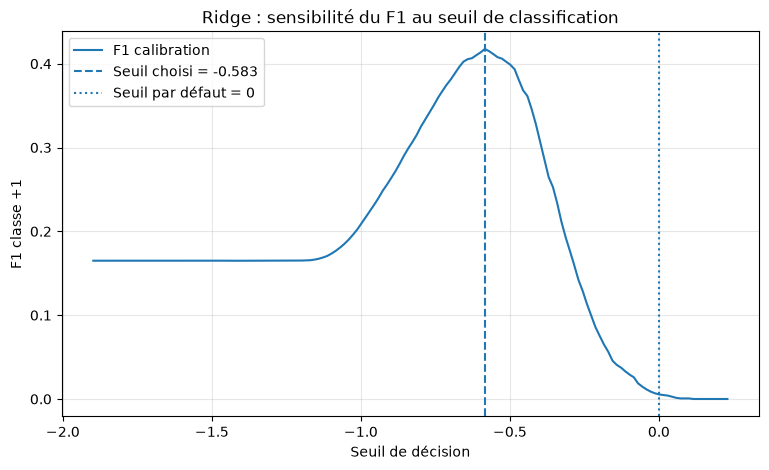

In [182]:
# Diagnostic complémentaire pour le rapport : impact du seuil sur le F1.
# Le seuil est étudié sur calibration uniquement (aucune optimisation sur évaluation).
cal_scores_best = X_cal @ ridge_weights[best_lambda]
threshold_grid = np.linspace(np.min(cal_scores_best), np.max(cal_scores_best), 150)
f1_by_threshold = [classification_metrics(y_cal, predict_labels(cal_scores_best, t))["F1"]
                   for t in threshold_grid]
plt.figure(figsize=(9, 5))
plt.plot(threshold_grid, f1_by_threshold, label="F1 calibration")
plt.axvline(best_ridge_threshold, linestyle="--", label=f"Seuil choisi = {best_ridge_threshold:.3f}")
plt.axvline(0, linestyle=":", label="Seuil par défaut = 0")
plt.xlabel("Seuil de décision")
plt.ylabel("F1 classe +1")
plt.title("Ridge : sensibilité du F1 au seuil de classification")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('Ridge : sensibilité du F1 au seuil de classification.png', bbox_inches='tight')
plt.show()

## 8. Comparaison finale sur l’ensemble d’évaluation

**Une seule évaluation** après sélection sur calibration. Nous comparons les deux modèles au seuil 0 et à leur seuil calibré.

In [172]:
best_w = ridge_weights[best_lambda]
ridge_eval_scores = X_eval @ best_w

rows = [
    {"Modèle": "Baseline toujours -1", "λ": np.nan, "seuil": np.nan, **baseline},
    {"Modèle": "Least Squares / seuil 0", "λ": 0.0, "seuil": 0.0, **ls_eval_default},
    {"Modèle": "Least Squares / seuil calibré", "λ": 0.0, "seuil": ls_threshold, **ls_eval_tuned},
    {"Modèle": "Ridge / seuil 0", "λ": best_lambda, "seuil": 0.0,
     **classification_metrics(y_eval, predict_labels(ridge_eval_scores, 0.0))},
    {"Modèle": "Ridge / seuil calibré", "λ": best_lambda, "seuil": best_ridge_threshold,
     **classification_metrics(y_eval, predict_labels(ridge_eval_scores, best_ridge_threshold))},
]
comparison = pd.DataFrame(rows).set_index("Modèle")
display(comparison.round(4))
comparison.to_csv("plot/comparison.csv")

,λ,seuil,F1,Precision,Recall,Accuracy,TP,FP,FN,TN
Modèle,,,,,,,,,,
Baseline toujours -1,NaN,NaN,0.0000,0.0000,0.0000,0.9101,0,0,2950,29863
Least Squares / seuil 0,0.0,0.0000,0.0054,0.7273,0.0027,0.9102,8,3,2942,29860
Least Squares / seuil calibré,0.0,-0.5765,0.4089,0.3280,0.5427,0.8589,1601,3280,1349,26583
Ridge / seuil 0,0.0,0.0000,0.0047,0.7000,0.0024,0.9102,7,3,2943,29860
Ridge / seuil calibré,0.0,-0.5829,0.4079,0.3235,0.5519,0.8560,1628,3404,1322,26459


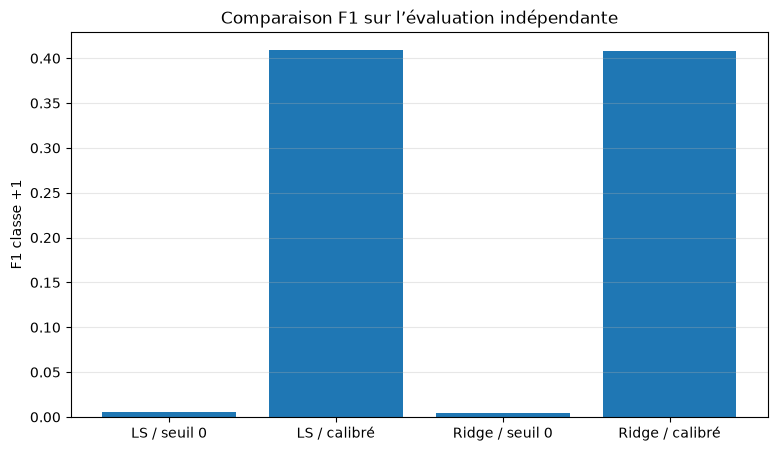

In [173]:
fig, ax = plt.subplots(figsize=(9, 5))
subset = comparison.loc[["Least Squares / seuil 0", "Least Squares / seuil calibré",
                         "Ridge / seuil 0", "Ridge / seuil calibré"]]
ax.bar(np.arange(len(subset)), subset["F1"].to_numpy())
ax.set_xticks(np.arange(len(subset)), ["LS / seuil 0", "LS / calibré", "Ridge / seuil 0", "Ridge / calibré"])
ax.set_ylabel("F1 classe +1")
ax.set_title("Comparaison F1 sur l’évaluation indépendante")
ax.grid(axis="y", alpha=0.3)
plt.show()

## 11. Soumissions finales : Least Squares et Ridge Regression


In [164]:
# FINAL SUBMISSION — Least Squares using the calibrated threshold from cell 10
from pathlib import Path
import numpy as np
from scipy.linalg import qr
from helpers import load_csv_data, create_csv_submission
from preprocessing import load_feature_names, clean_and_standardize
from implementations import least_squares

DATA_DIR = "data"  # Change to "data/dataset" if that is your CSV folder.
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

x_all_raw, x_test_raw, y_all, _, test_ids = load_csv_data(DATA_DIR)
names = load_feature_names(DATA_DIR)
tx_all, tx_test = clean_and_standardize(x_all_raw, x_test_raw, names)

# Recompute independent columns on the full preprocessed training set.
# QR with column pivoting avoids forming X.T @ X.
_, r, piv = qr(tx_all, mode="economic", pivoting=True)
diagonal = np.abs(np.diag(r))
tol = np.finfo(float).eps * max(tx_all.shape) * (diagonal[0] if len(diagonal) else 0)
rank = int(np.sum(diagonal > tol))
selected_cols = piv[:rank]

w_final_ls, final_ls_loss = least_squares(y_all.astype(float), tx_all[:, selected_cols])
ls_predictions = np.where(tx_test[:, selected_cols] @ w_final_ls >= ls_threshold, 1, -1)
assert len(ls_predictions) == len(test_ids)
create_csv_submission(test_ids, ls_predictions, str(output_dir / "submission_least_squares.csv"))
print(f"Least Squares submission saved; calibrated threshold = {ls_threshold:.6f}")


# Ridge Regression — optimal lambda and threshold from cell 12
from implementations import ridge_regression
assert "best_lambda" in globals() and "best_threshold" in globals(), (
    "Run cell 12 first to compute the optimal Ridge parameters."
)
w_final_ridge, final_ridge_loss = ridge_regression(
    y_all.astype(float), tx_all, best_lambda
)
ridge_predictions = np.where(
    tx_test @ w_final_ridge >= best_ridge_threshold, 1, -1
)
assert len(ridge_predictions) == len(test_ids)
assert np.isin(ridge_predictions, [-1, 1]).all()
create_csv_submission(test_ids, ridge_predictions, str(output_dir / "submission_ridge.csv"))
print(f"Ridge submission saved; lambda = {best_lambda:.6g}, threshold = {best_ridge_threshold:.6f}")


Least Squares submission saved; calibrated threshold = -0.576543
Ridge submission saved; lambda = 1.26896e-05, threshold = -0.582888
